# **NOTEBOOK 1, PRÁCTICA 2, APRENDIZAJE AUTOMATICO, CLUSTERING DE SEMILLAS**

Grupo 9

Álex Rodríguez Carbonero

David Naranjo Mateos


## Configuración inicial

Se añaden todas las bibliotecas necesarias para el proyecto. Y se cargan los datos "semillas.csv".

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from sklearn.preprocessing import MinMaxScaler, RobustScaler, StandardScaler
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.datasets import make_classification

# Cargar datos
data = pd.read_csv('semillas.csv')
X = data.drop('clase', axis=1)
y = data['clase']

# Fijar semilla para reproducibilidad
np.random.seed(100495724)

## Parte 1: Comprobación visual de los 3 scalers

A los scalers MiniMax, Robust y Standard se les ha sometido en un pipeline junto con Principal Component Analysis (PCA) para obtener las primeras dos componentes principales (PC1 y PC2), y visualiar los datos en dos dimensiones, 2D, de cada una de las tres escalas.

Cada una de las gráficas incluye colores que representan las clases originales, y se puede observar que los datos se separan de manera clara en las dos dimensiones.

Además de que se calcula la varianza de las dos primeras componentes principales, y la distancia entre los centroides de las clases para poder evaluar la separación entre las clases.

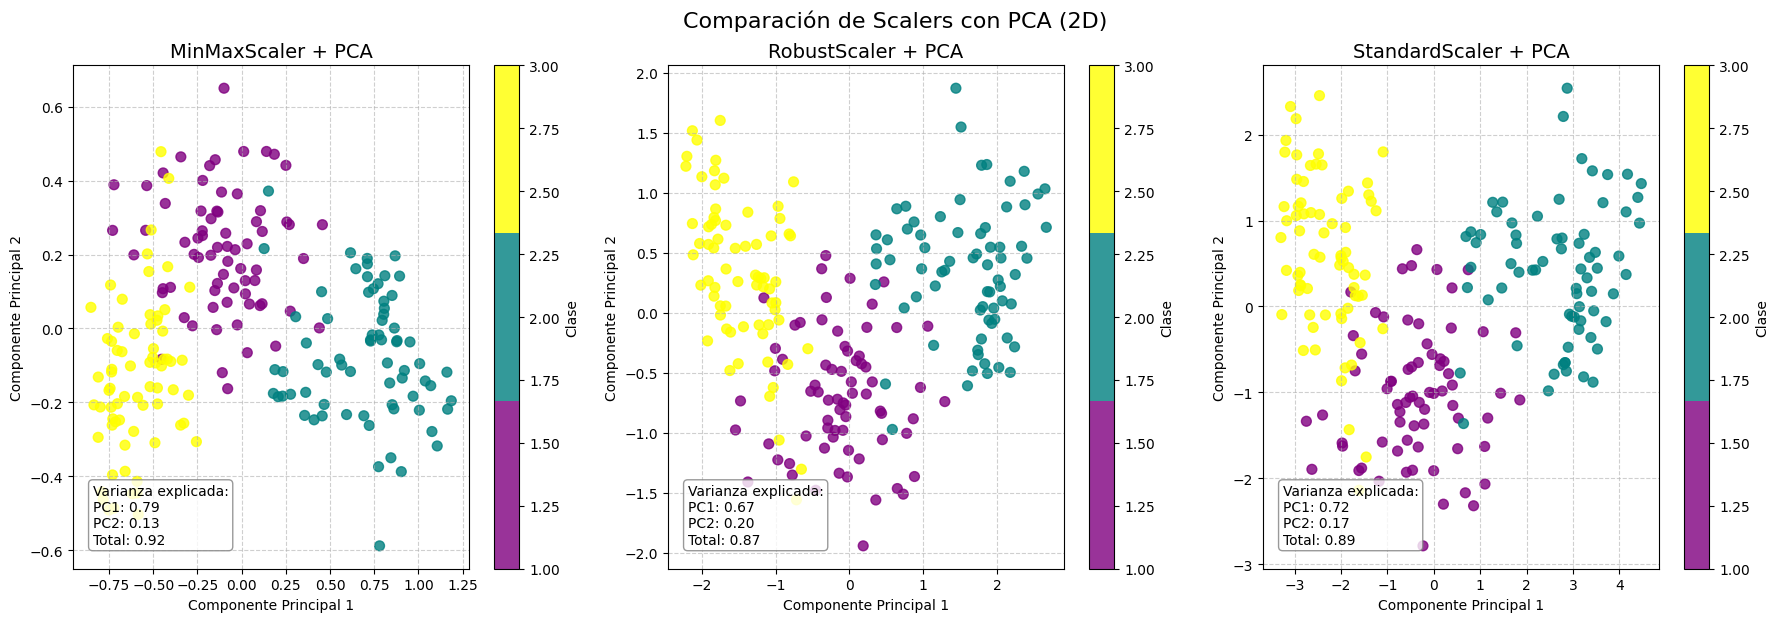


Comparación detallada:
     Escalador  Varianza Total  Distancia Media  Distancia Mínima  Separación Total  Puntuación General
StandardScaler          0.8898           3.6363            2.5406           10.9089              0.9923
  RobustScaler          0.8691           2.2520            1.6930            6.7559              0.7129
  MinMaxScaler          0.9181           0.9111            0.5893            2.7332              0.4333


In [2]:
# Configurar colores personalizados para las clases
colors = ['purple', 'teal', 'yellow']
custom_cmap = ListedColormap(colors)

# Definir escaladores
scalers = {
    'MinMaxScaler': MinMaxScaler(),
    'RobustScaler': RobustScaler(),
    'StandardScaler': StandardScaler()
}

# Preparar figura
plt.figure(figsize=(18, 6))
results = []

for i, (name, scaler) in enumerate(scalers.items()):
    # Pipeline: scaler + PCA
    pipeline = Pipeline([
        ('scaler', scaler),
        ('pca', PCA(n_components=2))
    ])
    X_transformed = pipeline.fit_transform(X)

    # Subgráfico
    ax = plt.subplot(1, 3, i + 1)
    scatter = plt.scatter(
        X_transformed[:, 0], X_transformed[:, 1],
        c=y, cmap=custom_cmap, alpha=0.8, s=50
    )
    plt.title(f'{name} + PCA', fontsize=14)
    plt.xlabel('Componente Principal 1')
    plt.ylabel('Componente Principal 2')
    plt.colorbar(scatter, label='Clase')
    plt.grid(True, linestyle='--', alpha=0.6)

    # Varianza explicada
    pca = pipeline.named_steps['pca']
    explained_var = pca.explained_variance_ratio_
    plt.annotate(
        f"Varianza explicada:\nPC1: {explained_var[0]:.2f}\nPC2: {explained_var[1]:.2f}\nTotal: {sum(explained_var):.2f}",
        xy=(0.05, 0.05), xycoords='axes fraction',
        bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="gray", alpha=0.8),
        fontsize=10
    )

    # Centroides y distancias
    centroids = [np.mean(X_transformed[y == cls], axis=0) for cls in np.unique(y)]
    distances = [
        np.linalg.norm(centroids[j] - centroids[k])
        for j in range(len(centroids)) for k in range(j + 1, len(centroids))
    ]

    # Guardar métricas
    results.append({
        'Escalador': name,
        'Varianza Total': sum(explained_var),
        'Distancia Media': np.mean(distances),
        'Distancia Mínima': min(distances),
        'Separación Total': sum(distances)
    })

plt.tight_layout()
plt.suptitle('Comparación de Scalers con PCA (2D)', fontsize=16, y=1.03)
plt.show()

# Crear DataFrame de resultados
df = pd.DataFrame(results)

# Normalizar métricas para puntuación compuesta
for col in ['Varianza Total', 'Distancia Media', 'Distancia Mínima', 'Separación Total']:
    df[f'{col} (norm)'] = df[col] / df[col].max()

df['Puntuación General'] = df[[col + ' (norm)' for col in ['Varianza Total', 'Distancia Media', 'Distancia Mínima', 'Separación Total']]].mean(axis=1)
df_sorted = df.sort_values('Puntuación General', ascending=False)

# Mostrar tabla
print("\nComparación detallada:")
print(df_sorted[['Escalador', 'Varianza Total', 'Distancia Media', 'Distancia Mínima', 'Separación Total', 'Puntuación General']].round(4).to_string(index=False))

### Conclusiones sobre los scalers
Tras un análisis de las visualizaciones y las métricas obtenidas, se concluye en que **MinMaxScaler** conserva la mayor varianza total (0.9181), pero no garantiza una buena separación entre clases.
**RobustScaler** tiene una separación moderada, pero no destaca en ninguna métrica. Y **StandardScaler** retiene casi tanta varianza como MinMaxScaler (0.8898) y logra una separación mucho mejor entre las clases, con la mayor distancia media, mínima y total entre centroides.
Es por esto que **StandardScaler** ha sido elegido como el scaler más apropiado para este problema, ya que ofrece un buen balance entre retención de estructura (varianza) y separación entre clases.

## Parte 2: Aplicación de las tres técnicas de clustering.

En esta parte, se aplicarán las tres técnicas de clustering estudiadas en clase: K-Means, Clustering jerárquico y DBSCAN. Y se comparan y discuten los resultados que se obtienen ademád de definir los hiper-parámetros más importantes para cada técnica.





In [3]:
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.neighbors import NearestNeighbors
import seaborn as sns

pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('pca', PCA(n_components=2))
])
X_2d = pipeline.fit_transform(X)

### ***K-MEANS Clustering***

Se utilizará el método del codo para estimar el número de clusters. Se usará el método de silueta para evaluar la calidad de los clusters.

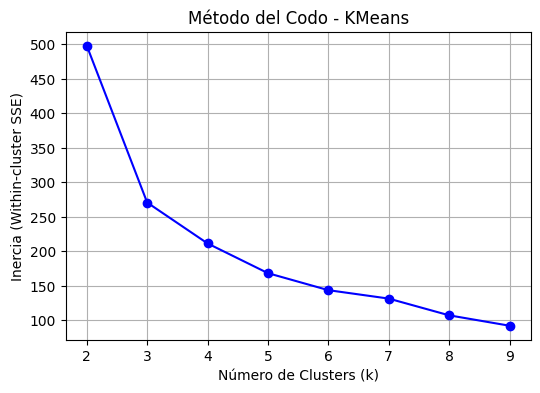

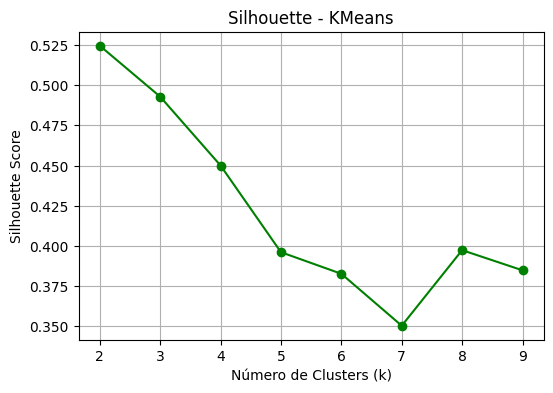

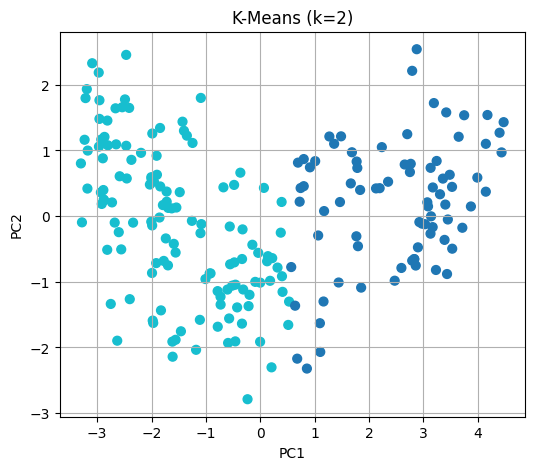

In [4]:
# Método del codo
inertias = []
K_range = range(2, 10)
for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(X_2d)
    inertias.append(kmeans.inertia_)

plt.figure(figsize=(6, 4))
plt.plot(K_range, inertias, 'bo-')
plt.xlabel('Número de Clusters (k)')
plt.ylabel('Inercia (Within-cluster SSE)')
plt.title('Método del Codo - KMeans')
plt.grid(True)
plt.show()

# Silhouette scores
sil_scores = []
for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=100495724)
    labels = kmeans.fit_predict(X_2d)
    score = silhouette_score(X_2d, labels)
    sil_scores.append(score)

plt.figure(figsize=(6, 4))
plt.plot(K_range, sil_scores, 'go-')
plt.xlabel('Número de Clusters (k)')
plt.ylabel('Silhouette Score')
plt.title('Silhouette - KMeans')
plt.grid(True)
plt.show()

# Elegimos el mejor K según el silhouette (u observación visual del codo)
best_k = K_range[np.argmax(sil_scores)]
kmeans = KMeans(n_clusters=best_k, random_state=100495724)
kmeans_labels = kmeans.fit_predict(X_2d)

# Visualización final
plt.figure(figsize=(6, 5))
plt.scatter(X_2d[:, 0], X_2d[:, 1], c=kmeans_labels, cmap='tab10', s=40)
plt.title(f'K-Means (k={best_k})')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.grid(True)
plt.show()

### ***CLUSTERING JERÁRQUICO***

Se probarán varias funciones de linkage y se determinará el número de clusters adecuado.


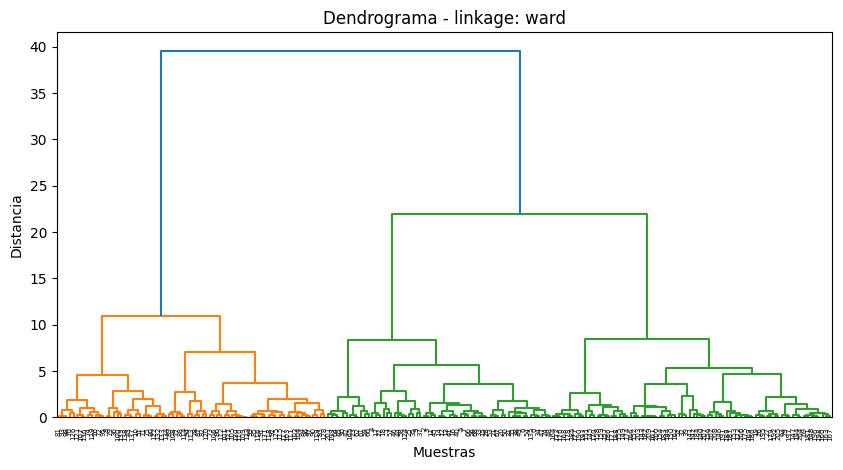

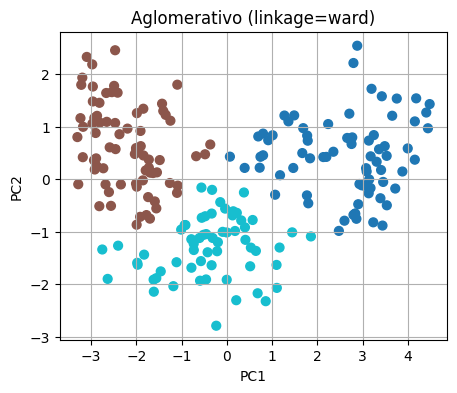

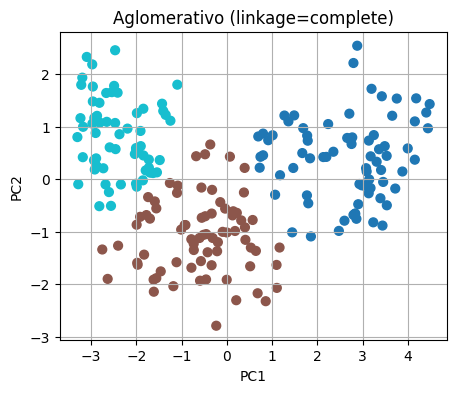

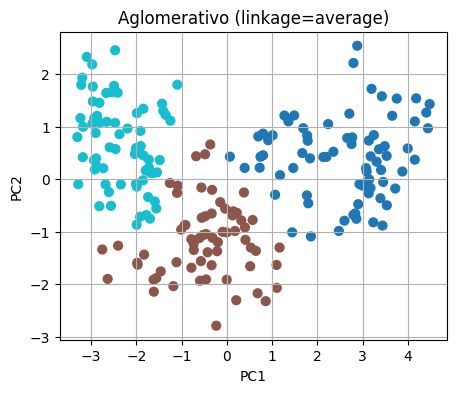

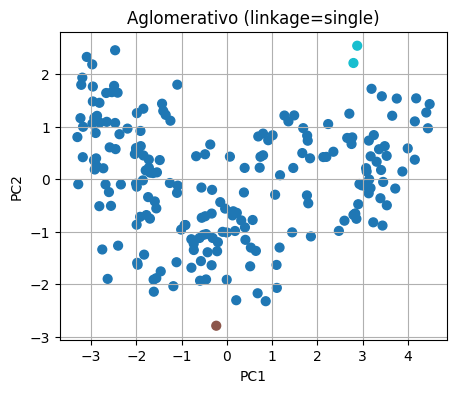

In [5]:
# Dendrograma con linkage 'ward'
plt.figure(figsize=(10, 5))
linked = linkage(X_2d, method='ward')
dendrogram(linked)
plt.title('Dendrograma - linkage: ward')
plt.xlabel('Muestras')
plt.ylabel('Distancia')
plt.show()

# Probamos varios linkages con 3 clusters (puedes ajustar este número observando el dendrograma)
for method in ['ward', 'complete', 'average', 'single']:
    clustering = AgglomerativeClustering(n_clusters=3, linkage=method)
    labels = clustering.fit_predict(X_2d)
    plt.figure(figsize=(5, 4))
    plt.scatter(X_2d[:, 0], X_2d[:, 1], c=labels, cmap='tab10', s=40)
    plt.title(f'Aglomerativo (linkage={method})')
    plt.xlabel('PC1')
    plt.ylabel('PC2')
    plt.grid(True)
    plt.show()

### ***DBSCAN***

Se ajustan los hiperparámetros eps y min_samples basándose en un gráfico de distancias.

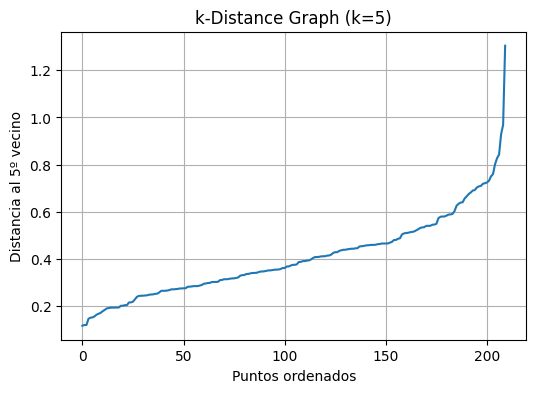

Mejor eps: 0.5, Mejor Silhouette Score: 0.3325


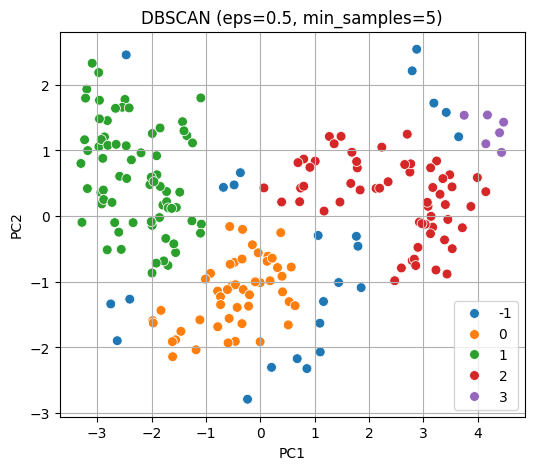

In [6]:
# Usamos NearestNeighbors para estimar buen valor de eps
neighbors = NearestNeighbors(n_neighbors=5)
neighbors_fit = neighbors.fit(X_2d)
distances, indices = neighbors_fit.kneighbors(X_2d)
k_distances = np.sort(distances[:, -1])

plt.figure(figsize=(6, 4))
plt.plot(k_distances)
plt.title("k-Distance Graph (k=5)")
plt.xlabel("Puntos ordenados")
plt.ylabel("Distancia al 5º vecino")
plt.grid(True)
plt.show()

# Ajuste de eps para DBSCAN
best_eps = None
best_score = -1

for eps in np.arange(0.1, 1.0, 0.1):  # Ajusta el rango según sea necesario
    dbscan = DBSCAN(eps=eps, min_samples=5)
    labels = dbscan.fit_predict(X_2d)
    if len(set(labels)) > 1:  # Evitar casos donde todos los puntos están en un solo cluster
        score = silhouette_score(X_2d, labels)
        if score > best_score:
            best_score = score
            best_eps = eps

print(f"Mejor eps: {best_eps}, Mejor Silhouette Score: {best_score:.4f}")

# Visualización con el mejor eps
dbscan = DBSCAN(eps=best_eps, min_samples=5)
dbscan_labels = dbscan.fit_predict(X_2d)

plt.figure(figsize=(6, 5))
sns.scatterplot(x=X_2d[:, 0], y=X_2d[:, 1], hue=dbscan_labels, palette='tab10', legend='full', s=50)
plt.title(f'DBSCAN (eps={best_eps}, min_samples=5)')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.grid(True)

Tras realizar una comparativa a los tres métodos de clustering: (K-Means, Clustering Jerárquico y DBSCAN.) Para poder elegir el mejor, se centran en aspectos como la claridad con que separaban los grupos, cómo lidiaban con datos raros, si los resultados eran fáciles de entender y lo fácil que era verlos gráficamente.

***K-Means*** destaca en varios puntos. Usando el método del codo, se pudo conocer cuántos grupos eran ideales (2), y la puntuación de Silhouette mostró que estaban bien separados. Esta técnica creó grupos apretados y claros, lo que hace que sea fácil entenderlos. Pero tiene sus contras, como asumir que los grupos son redondos y del mismo tamaño, algo que no siempre es cierto. Además, le afectan mucho los datos raros, lo que puede empeorar el resultado.

Por su parte, ***Clustering Jerárquico*** destaca porque no necesita la especificación de los grupos, dejando el ajuste al dendrograma. También es flexible porque permite usar diferentes formas de conectar los datos (como ward, complete, average o single), y ward fue la que mejor funcionó. Esta técnica sirve para ver si hay niveles de organización en los datos, pero lo malo es que consume muchos recursos, sobre todo con grandes cantidades de datos.

***DBSCAN***, por otro lado, tiene una forma distinta de ver las cosas, encontrando grupos de forma libre sin esperar formas concretas. Su habilidad para ver datos raros y tratarlos como ruido es un punto a favor. Tampoco necesita especificación de grupos al igual que Clustering Jerárquico. Eso sí, su éxito depende mucho de elegir bien los parámetros eps y min_samples. En los resultados se recoge una puntuación de Silhouette más baja que los otros, lo que indica que no separó los grupos tan bien.

En conclusión, si se centra en la separación de los grupos, lo rápido que trabaja y lo fácil que es entenderlo, K-Means es el mejor clustering para este caso en particular. Aunque DBSCAN es bueno para los datos raros, aquí no había mucho ruido, y los datos se adaptaban bien a lo que K-Means puede hacer.

### Parte 3: Análisis


### Comprobación visual
Como ya se ha comentado anteriormente, pero en este caso un poco más resumido, a la pregunta de ***"¿cuál de los métodos de clustering captura mejor la estructura de clusters de este problema?"***
1. **K-Means:**
   - Los clusters son compactos y bien separados en el espacio reducido por PCA.
   - Sin embargo, la técnica asume formas esféricas, lo que puede no ser ideal si los datos tienen formas más complejas.

2. **Clustering Jerárquico:**
   - El método `ward` produce clusters compactos y bien definidos.
   - Otros métodos de linkage (`complete`, `average`) generan clusters más dispersos.

3. **DBSCAN:**
   - Identifica estructuras no esféricas y detecta puntos como ruido.
   - Sin embargo, los clusters no están tan bien separados como en K-Means o Clustering Jerárquico.

En general, **K-Means** parece capturar mejor la estructura de los datos, ya que los clusters son compactos y bien definidos.

In [7]:
from sklearn.metrics import homogeneity_score, completeness_score

# Ejemplo para K-Means
print("Relación entre clusters y clases originales (K-Means):")
contingency_table = pd.crosstab(kmeans_labels, y)
print(contingency_table)

# Métricas de homogeneidad y completitud
homogeneity = homogeneity_score(y, kmeans_labels)
completeness = completeness_score(y, kmeans_labels)
print(f"Homogeneidad: {homogeneity:.4f}")
print(f"Completitud: {completeness:.4f}")

Relación entre clusters y clases originales (K-Means):
clase   1   2   3
row_0            
0      10  70   0
1      60   0  70
Homogeneidad: 0.4804
Completitud: 0.7943


In [8]:
# Relación entre clusters y clases originales (Clustering Jerárquico)
hierarchical_labels = AgglomerativeClustering(n_clusters=3, linkage='ward').fit_predict(X_2d)

print("Relación entre clusters y clases originales (Clustering Jerárquico):")
contingency_table_hierarchical = pd.crosstab(hierarchical_labels, y)
print(contingency_table_hierarchical)

# Métricas de homogeneidad y completitud
homogeneity_hierarchical = homogeneity_score(y, hierarchical_labels)
completeness_hierarchical = completeness_score(y, hierarchical_labels)
print(f"Homogeneidad: {homogeneity_hierarchical:.4f}")
print(f"Completitud: {completeness_hierarchical:.4f}")

Relación entre clusters y clases originales (Clustering Jerárquico):
clase   1   2   3
row_0            
0       5  68   0
1       9   0  67
2      56   2   3
Homogeneidad: 0.7116
Completitud: 0.7144


In [9]:
# Relación entre clusters y clases originales (DBSCAN)
print("Relación entre clusters y clases originales (DBSCAN):")
contingency_table_dbscan = pd.crosstab(dbscan_labels, y)
print(contingency_table_dbscan)

# Métricas de homogeneidad y completitud
homogeneity_dbscan = homogeneity_score(y, dbscan_labels)
completeness_dbscan = completeness_score(y, dbscan_labels)
print(f"Homogeneidad: {homogeneity_dbscan:.4f}")
print(f"Completitud: {completeness_dbscan:.4f}")

Relación entre clusters y clases originales (DBSCAN):
clase   1   2   3
row_0            
-1     17   6   1
 0     44   2   3
 1      6   0  66
 2      3  56   0
 3      0   6   0
Homogeneidad: 0.6993
Completitud: 0.5438


### Relación con las clases originales
Se evaluó la relación entre los clusters obtenidos y las clases originales (`clase`) utilizando tablas de contingencia y métricas de homogeneidad y completitud:

1. **K-Means (k = 2):**
   - Homogeneidad: `0.4804`.
   - Completitud: `0.7943`.
   - Con dos clusters, uno de ellos reúne casi todas las semillas de las clases 1 y 3. La completitud es alta porque cada clase cae casi entera en un cluster, pero la homogeneidad es la más baja de las tres técnicas.

2. **Clustering Jerárquico (ward, 3 clusters):**
   - Homogeneidad: `0.7116`.
   - Completitud: `0.7144`.
   - Cada cluster está formado sobre todo por una clase, y es el resultado más equilibrado entre las dos métricas.

3. **DBSCAN:**
   - Homogeneidad: `0.6993`.
   - Completitud: `0.5438`.
   - Los clusters son bastante puros, pero las clases quedan repartidas en 4 clusters y 24 puntos se marcan como ruido, por lo que la completitud baja.

En general, el **Clustering Jerárquico** muestra la mejor correspondencia con las clases originales. K-Means obtiene la mejor silueta, pero con k = 2 no puede distinguir las tres clases.

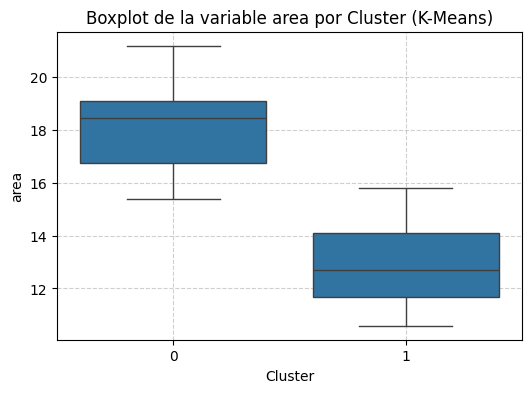

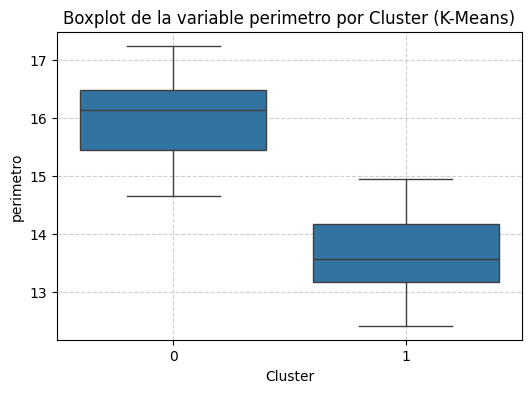

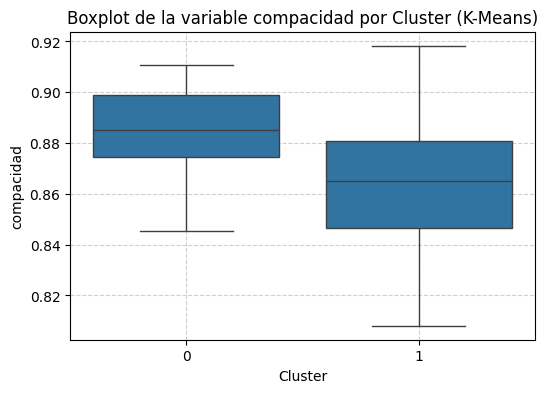

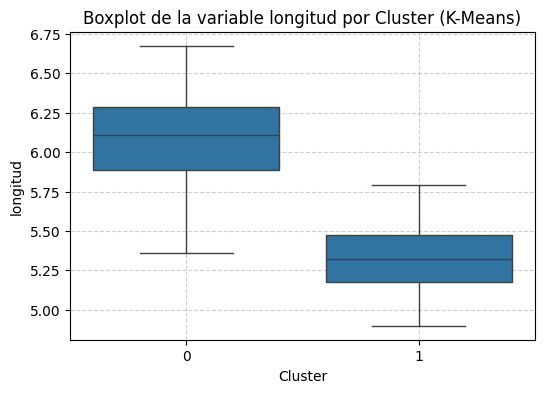

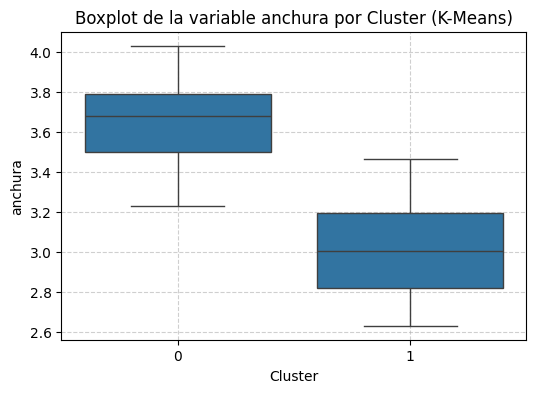

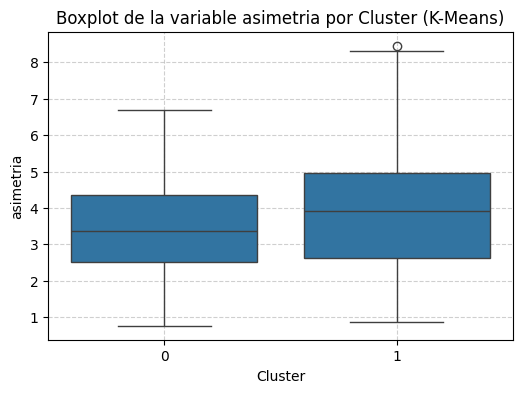

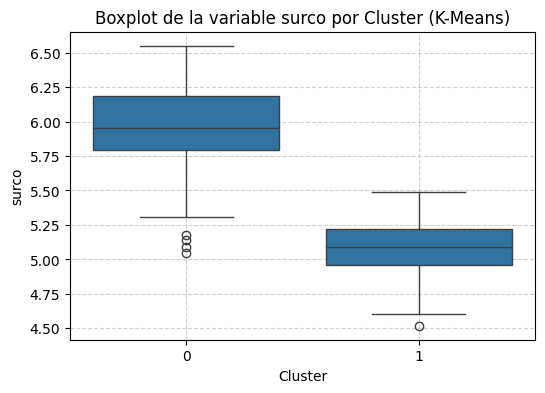

In [10]:
# Agregar etiquetas de clusters al DataFrame original
data['Cluster_KMeans'] = kmeans_labels

# Crear boxplots para cada característica
for column in X.columns:
    plt.figure(figsize=(6, 4))
    sns.boxplot(x='Cluster_KMeans', y=column, data=data)
    plt.title(f'Boxplot de la variable {column} por Cluster (K-Means)')
    plt.xlabel('Cluster')
    plt.ylabel(column)
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.show()

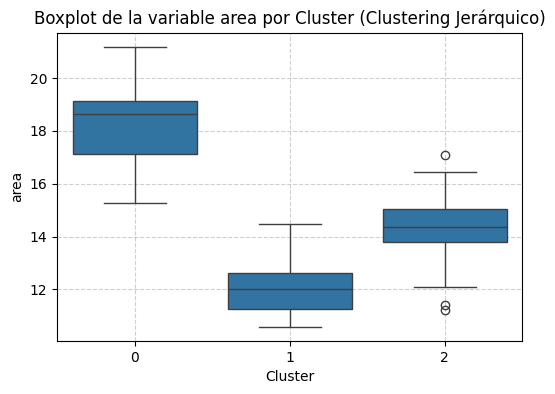

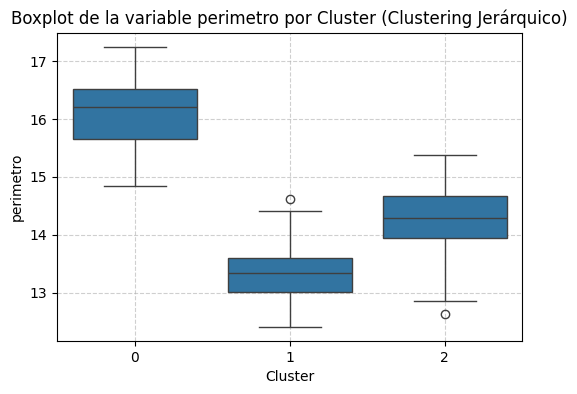

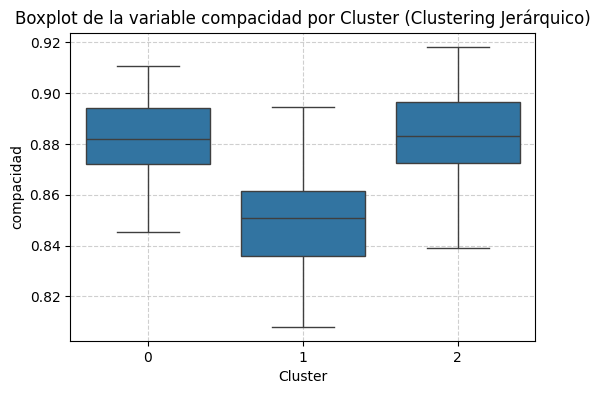

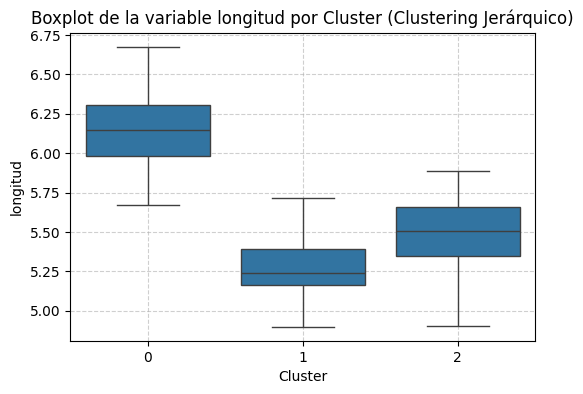

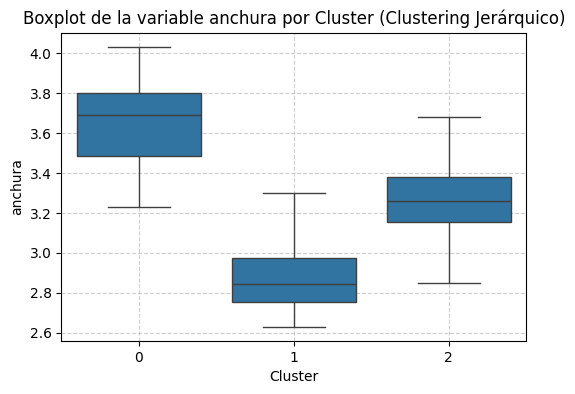

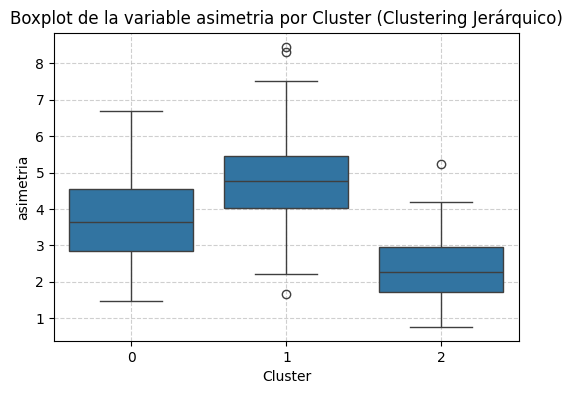

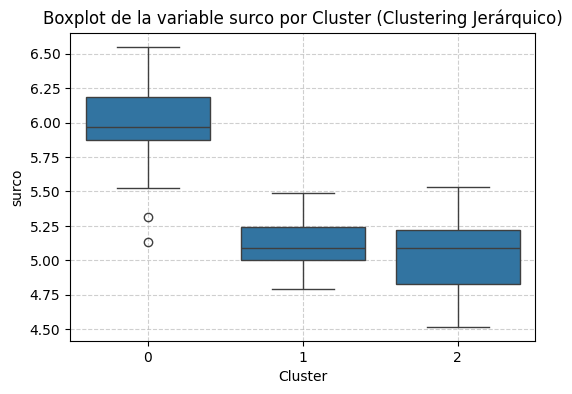

In [11]:
# Agregar etiquetas de clusters al DataFrame original
data['Cluster_Hierarchical'] = hierarchical_labels

# Crear boxplots para cada característica
for column in X.columns:
    plt.figure(figsize=(6, 4))
    sns.boxplot(x='Cluster_Hierarchical', y=column, data=data)
    plt.title(f'Boxplot de la variable {column} por Cluster (Clustering Jerárquico)')
    plt.xlabel('Cluster')
    plt.ylabel(column)
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.show()

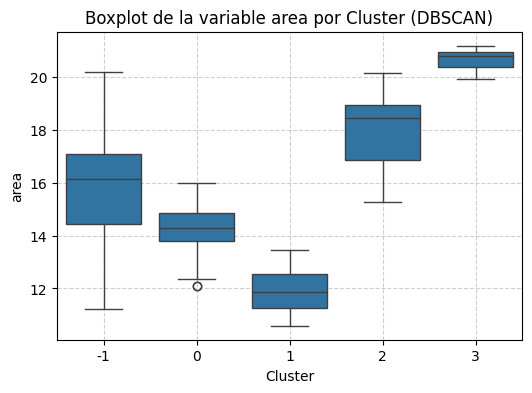

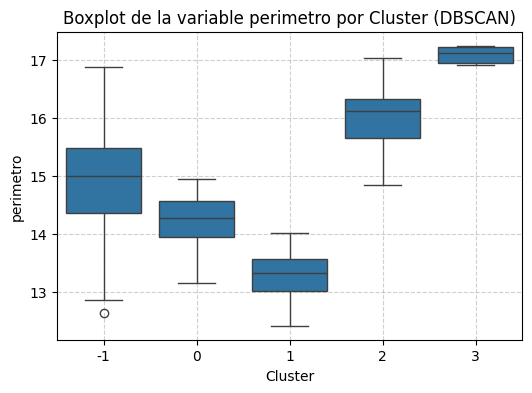

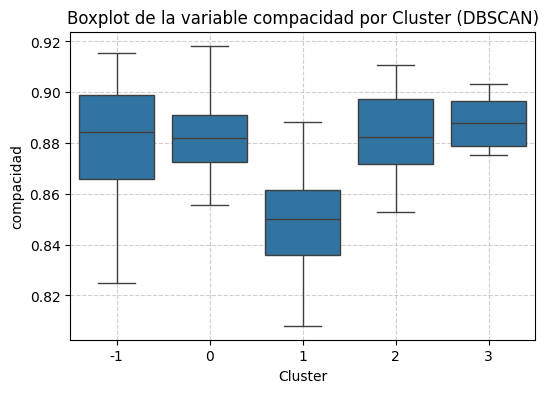

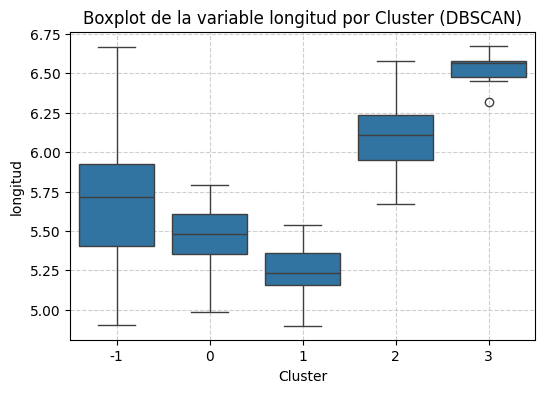

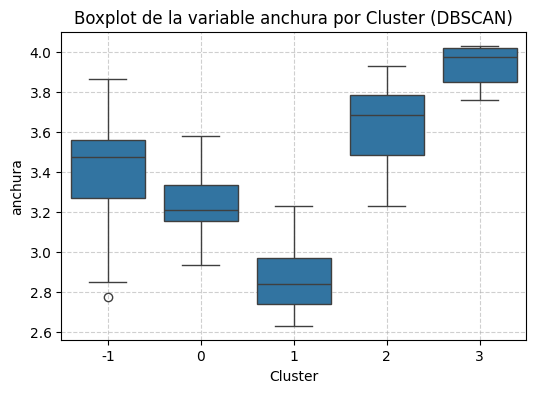

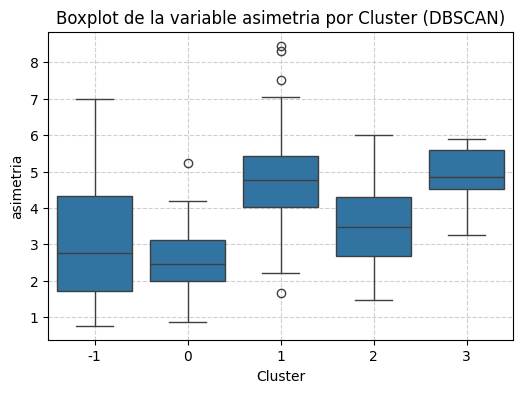

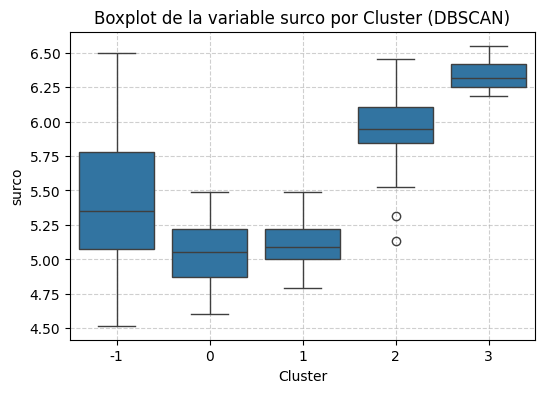

In [12]:
# Agregar etiquetas de clusters al DataFrame original
data['Cluster_DBSCAN'] = dbscan_labels

# Crear boxplots para cada característica
for column in X.columns:
    plt.figure(figsize=(6, 4))
    sns.boxplot(x='Cluster_DBSCAN', y=column, data=data)
    plt.title(f'Boxplot de la variable {column} por Cluster (DBSCAN)')
    plt.xlabel('Cluster')
    plt.ylabel(column)
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.show()

### Interpretación de los clusters
Se generaron boxplots para analizar las características de los clusters obtenidos con cada técnica:

1. **K-Means:**
   - Los boxplots muestran que los clusters están bien separados en la mayoría de las características.
   - Esto indica que K-Means logra una buena partición de los datos.

2. **Clustering Jerárquico:**
   - Los boxplots son similares a los de K-Means, pero con una mayor superposición en algunas características.
   - Esto sugiere que Clustering Jerárquico no separa tan bien los datos como K-Means.

3. **DBSCAN:**
   - Los boxplots muestran una mayor superposición entre los clusters.
   - Esto indica que DBSCAN no logra una separación tan clara como K-Means o Clustering Jerárquico.

En general, los boxplots confirman que **K-Means** es la técnica que mejor separa los datos en este problema.